# DSA5206: three-model prediction-only error analysis
This independent notebook reads actual held-out predictions. It never loads model weights, extracts features, fits regressions or changes experimental outputs. All results below require a successfully validated real prediction CSV; there are no stored numerical findings or example clinical figures.

**Verified input filename:** the existing `EVA_X_Comparison.ipynb` exports `three_model_heldout_predictions.csv`, not `all_three_model_heldout_predictions.csv`. We inspect the export code again at runtime rather than inventing a fallback or deriving predictions from summary means. Default input folder: `/content/duong-eva-x-results/`.

Read `ERROR_ANALYSIS.md` for Colab setup and privacy instructions. All six figures use unique-image or equal-image patient summaries; repeated held-out predictions are not treated as independent X-rays.


In [1]:
!git clone --branch error-analysis \
https://github.com/ZIYINGLAN/nus_DSA5206_GROUPPROJECT.git \
/content/nus_DSA5206_GROUPPROJECT

Cloning into '/content/nus_DSA5206_GROUPPROJECT'...
remote: Enumerating objects: 92, done.
remote: Counting objects: 100% (92/92), done.
remote: Compressing objects: 100% (77/77), done.
remote: Total 92 (delta 30), reused 43 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (92/92), 8.66 MiB | 12.94 MiB/s, done.
Resolving deltas: 100% (30/30), done.


In [3]:
!git clone --branch error-analysis \
https://github.com/ZIYINGLAN/nus_DSA5206_GROUPPROJECT.git \
/content/nus_DSA5206_GROUPPROJECT

Cloning into '/content/nus_DSA5206_GROUPPROJECT'...
remote: Enumerating objects: 92, done.
remote: Counting objects: 100% (92/92), done.
remote: Compressing objects: 100% (77/77), done.
remote: Total 92 (delta 30), reused 43 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (92/92), 8.66 MiB | 12.57 MiB/s, done.
Resolving deltas: 100% (30/30), done.


In [4]:
from pathlib import Path

repo = Path("/content/nus_DSA5206_GROUPPROJECT")

print("Repository exists:", repo.is_dir())
print("Error Analysis module:",
      (repo / "error_analysis_methods.py").is_file())
print("Notebook:",
      (repo / "Error_Analysis.ipynb").is_file())

Repository exists: True
Error Analysis module: True
Notebook: True


In [3]:
import os

os.environ["DUONG_EVA_RESULTS_DIR"] = (
    "/content/drive/MyDrive/duong-eva-x-results"
)

In [4]:
# Prediction-only dependencies; no torch, timm or checkpoints needed for analysis.
%pip install numpy==1.26.4 pandas==2.2.3 matplotlib==3.9.2


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 60.8 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.2
    Uninstalling pandas-2.2.2:
      Successfully uninstalled pandas-2.2.2
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstalled matplotlib-3.10.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the sourc

In [5]:
import sys
import importlib.util
from pathlib import Path

repo = Path("/content/nus_DSA5206_GROUPPROJECT").resolve()
module_path = repo / "error_analysis_methods.py"

print("Repository exists:", repo.is_dir())
print("Module exists:", module_path.is_file())

assert repo.is_dir(), "GitHub repository not found"
assert module_path.is_file(), "error_analysis_methods.py not found"

# 通过绝对文件路径加载模块
spec = importlib.util.spec_from_file_location(
    "error_analysis_methods",
    str(module_path)
)

module = importlib.util.module_from_spec(spec)
sys.modules["error_analysis_methods"] = module

try:
    spec.loader.exec_module(module)
except Exception:
    sys.modules.pop("error_analysis_methods", None)
    raise

print("Successfully loaded:", module.__file__)

Repository exists: True
Module exists: True
Successfully loaded: /content/nus_DSA5206_GROUPPROJECT/error_analysis_methods.py


In [10]:
from pathlib import Path

folders = [
    Path("/content/duong-eva-x-results"),
    Path("/content/drive/MyDrive/duong-eva-x-results"),
    Path("/content/drive/MyDrive"),
]

for folder in folders:
    print(f"\nChecking: {folder}")
    print("Exists:", folder.exists())

    if folder.is_dir():
        matches = list(folder.rglob("three_model_heldout_predictions.csv"))
        for match in matches[:10]:
            print("FOUND:", match)


Checking: /content/duong-eva-x-results
Exists: False

Checking: /content/drive/MyDrive/duong-eva-x-results
Exists: True
FOUND: /content/drive/MyDrive/duong-eva-x-results/three_model_heldout_predictions.csv

Checking: /content/drive/MyDrive
Exists: True
FOUND: /content/drive/MyDrive/duong-eva-x-results/three_model_heldout_predictions.csv


In [11]:
import os
from pathlib import Path

# 指向 Google Drive 中已备份的实验结果
os.environ["DUONG_EVA_RESULTS_DIR"] = (
    "/content/drive/MyDrive/duong-eva-x-results"
)

results_dir = Path(os.environ["DUONG_EVA_RESULTS_DIR"])

print("Input directory:", results_dir)

for filename in [
    "three_model_heldout_predictions.csv",
    "patient_split_audit.json",
    "reproducibility_manifest.json"
]:
    print(filename, (results_dir / filename).is_file())

Input directory: /content/drive/MyDrive/duong-eva-x-results
three_model_heldout_predictions.csv True
patient_split_audit.json True
reproducibility_manifest.json True


In [12]:
# Optional: mount Drive if previous outputs are stored there.
from google.colab import drive
drive.mount('/content/drive')
import os,json
from pathlib import Path
import pandas as pd
from IPython.display import display,Image
REPO_DIR=Path(os.environ.get('DUONG_REPO_DIR','/content/nus_DSA5206_GROUPPROJECT')).resolve()
INPUT_DIR=Path(os.environ.get('DUONG_EVA_RESULTS_DIR','/content/duong-eva-x-results')).resolve()
OUTPUT_DIR=Path(os.environ.get('DUONG_ERROR_RESULTS_DIR','/content/duong-error-analysis-results')).resolve()
import sys
sys.path.insert(0,str(REPO_DIR))
from error_analysis_methods import (verified_prediction_filename,validate_predictions,analyze_predictions,
    presentation_table,export_analysis,FIGURE_NAMES,file_sha256)
source_notebook=REPO_DIR/'EVA_X_Comparison.ipynb'
verified_name=verified_prediction_filename(source_notebook)
PREDICTIONS=INPUT_DIR/verified_name
AUDIT=INPUT_DIR/'patient_split_audit.json'
MANIFEST=INPUT_DIR/'reproducibility_manifest.json'
print('Verified source export:',verified_name)
assert OUTPUT_DIR!=REPO_DIR and not OUTPUT_DIR.is_relative_to(REPO_DIR)
assert OUTPUT_DIR!=INPUT_DIR and not OUTPUT_DIR.is_relative_to(INPUT_DIR)
if OUTPUT_DIR.exists():raise FileExistsError('Output already exists; choose a new DUONG_ERROR_RESULTS_DIR, never overwrite prior results')
for p in [PREDICTIONS,AUDIT]:
    if not p.is_file():raise FileNotFoundError(f'Required real-data input is missing: {p}. No synthetic clinical substitutes are generated.')
input_paths={'predictions':PREDICTIONS,'patient_split_audit':AUDIT,'source_notebook':source_notebook}
if MANIFEST.is_file():input_paths['source_manifest']=MANIFEST
input_hashes={key:file_sha256(path) for key,path in input_paths.items()}


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Verified source export: three_model_heldout_predictions.csv


## 1. Validate every record before analysis
Required columns: model, target, seed, row_index, filename, patientid, y_true, y_pred. Require the exact three pipeline identifiers, two targets and all 50 seeds (0–49) for every model/target, unique prediction keys, finite scores, stable filename/patient/row identity and true labels, and complete model pairing. Source patient IDs are read as strings to preserve their CSV spelling, not renumbered or silently normalized.

The prior `patient_split_audit.json` is mandatory: validate every observed test index against its seed's actual audit, for both targets and all models; validate patient separation from train/test IDs (or derive IDs from the available full source manifest). Images are not expected to appear in every split. Missing entire paired observations are errors, not reasons to silently drop rows. Check ordered cohort/labels and 94 images/65 patients when the source manifest is supplied. A missing manifest is recorded explicitly; it is not replaced with invented provenance. Audit and manifest checks establish consistency of supplied artifacts, not independent certification of model training or checkpoint provenance.


In [13]:
records=pd.read_csv(PREDICTIONS,dtype={'filename':str,'patientid':str})
audit=json.loads(AUDIT.read_text())
source_manifest=json.loads(MANIFEST.read_text()) if MANIFEST.is_file() else None
validated,cohort,validation=validate_predictions(records,audit,source_manifest)
print(json.dumps(validation,indent=2))
if source_manifest is None:print('Source reproducibility manifest unavailable: cohort-source identity remains incompletely verified.')
# Do not display raw source identities in presentation-ready notebook output.
display(presentation_table(validated).head())


{
  "manifest_available": true,
  "external_membership_audit_verified": true,
  "audited_images": 94,
  "audited_patients": 65,
  "observed_images": 94,
  "observed_patients": 65,
  "unobserved_images": 0,
  "records": 14304,
  "seeds": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    39,
    40,
    41,
    42,
    43,
    44,
    45,
    46,
    47,
    48,
    49
  ]
}


,model,target,seed,row_index,y_true,y_pred,case_id,study_patient_id
0,DenseNet Lung Opacity + OLS,Geographic Extent,0,6,6.0,4.951242,C007,P039
1,EVA-X-Tiny + Ridge,Geographic Extent,0,6,6.0,4.759077,C007,P039
2,ResNet18 + Ridge,Geographic Extent,0,6,6.0,1.781129,C007,P039
3,DenseNet Lung Opacity + OLS,Geographic Extent,0,7,7.3,6.385564,C008,P039
4,EVA-X-Tiny + Ridge,Geographic Extent,0,7,7.3,5.233385,C008,P039


## 2. Estimands: predictions → images → patients
For matched `(target, seed, row_index)` observations, error = prediction − truth, absolute error = |error| and squared error = error². Compute EVA minus comparator absolute error **within each matched observation first**; negative favours EVA.

For each unique image/target/model, average only occasions actually held out. Report n appearances, mean signed error, mean/median absolute error, sample SD of signed error (N/A for one appearance), mean prediction and true score. Mean absolute error is not the absolute error of the mean prediction.

For each patient, first obtain each image's mean held-out errors, then average distinct-image means with equal image weights. Images with more test appearances do not get extra patient weight. Patient paired differences also average image paired differences equally. Summaries report total scored images, analyzed images and per-image appearance counts. Patients with no observed test predictions are not assigned zero errors; coverage is reported. The lower-EVA-error proportion uses analyzed patients as its denominator, with ties reported separately.

These summaries remove repeated appearances from the plotted unit counts, but shared patients/training sets across splits still create dependence. No naive significance test or independent-replication standard error is computed.


In [14]:
tables=analyze_predictions(validated,cohort)
display(presentation_table(tables['image_level_errors']).head())
display(presentation_table(tables['patient_level_errors']).head())
display(tables['patient_improvement_summary'])
display(presentation_table(tables['image_rankings']).head(12))


,target,row_index,case_id,study_patient_id,model,n_heldout,mean_signed_error,mean_absolute_error,median_absolute_error,std_signed_error,mean_prediction,y_true,overestimation_rate,underestimation_rate,zero_error_prediction_rate,mean_delta_abs_error_eva_dense,mean_delta_abs_error_eva_resnet
0,Geographic Extent,0,C001,P014,DenseNet Lung Opacity + OLS,26,0.592902,0.592902,0.610528,0.184584,2.892902,2.3,1.000000,0.000000,0.0,0.008969,-0.005343
1,Geographic Extent,0,C001,P014,EVA-X-Tiny + Ridge,26,0.533929,0.601871,0.562804,0.474468,2.833929,2.3,0.884615,0.115385,0.0,0.008969,-0.005343
2,Geographic Extent,0,C001,P014,ResNet18 + Ridge,26,0.360914,0.607214,0.595938,0.610742,2.660914,2.3,0.692308,0.307692,0.0,0.008969,-0.005343
3,Geographic Extent,1,C002,P014,DenseNet Lung Opacity + OLS,26,-1.557252,1.557252,1.543533,0.197220,2.442748,4.0,0.000000,1.000000,0.0,-0.592381,-0.103141
4,Geographic Extent,1,C002,P014,EVA-X-Tiny + Ridge,26,-0.839590,0.964871,0.883624,0.649981,3.160410,4.0,0.038462,0.961538,0.0,-0.592381,-0.103141


,target,study_patient_id,model,n_analyzed_images,mean_absolute_error,mean_signed_error,mean_prediction,overestimation_rate,underestimation_rate,zero_error_prediction_rate,mean_true_score,min_image_appearances,max_image_appearances,mean_image_appearances,n_scored_images,heldout_appearances_per_image,mean_delta_abs_error_eva_dense,mean_delta_abs_error_eva_resnet
0,Geographic Extent,P001,DenseNet Lung Opacity + OLS,1,3.524998,3.524998,5.524998,1.000000,0.000000,0.0,2.0,24,24,24.0,1,"{""C009"": 24}",-2.194997,-2.103482
1,Geographic Extent,P001,EVA-X-Tiny + Ridge,1,1.330001,1.260658,3.260658,0.958333,0.041667,0.0,2.0,24,24,24.0,1,"{""C009"": 24}",-2.194997,-2.103482
2,Geographic Extent,P001,ResNet18 + Ridge,1,3.433483,3.433483,5.433483,1.000000,0.000000,0.0,2.0,24,24,24.0,1,"{""C009"": 24}",-2.194997,-2.103482
3,Geographic Extent,P002,DenseNet Lung Opacity + OLS,2,0.455668,0.434177,1.434177,0.863636,0.136364,0.0,1.0,22,22,22.0,2,"{""C085"": 22, ""C086"": 22}",-0.192437,-0.835362
4,Geographic Extent,P002,EVA-X-Tiny + Ridge,2,0.263231,-0.019061,0.980939,0.477273,0.522727,0.0,1.0,22,22,22.0,2,"{""C085"": 22, ""C086"": 22}",-0.192437,-0.835362


,target,comparison,n_analyzed_patients,n_lower_EVA_error,proportion_lower_EVA_error,n_equal_error,mean_paired_difference
0,Geographic Extent,DenseNet,65,32,0.492308,0,-0.117588
1,Geographic Extent,ResNet18,65,51,0.784615,0,-0.488645
2,Opacity,DenseNet,65,31,0.476923,0,-0.080383
3,Opacity,ResNet18,65,45,0.692308,0,-0.239986


,target,row_index,case_id,study_patient_id,model,n_heldout,mean_signed_error,mean_absolute_error,median_absolute_error,std_signed_error,mean_prediction,y_true,overestimation_rate,underestimation_rate,zero_error_prediction_rate,mean_delta_abs_error_eva_dense,mean_delta_abs_error_eva_resnet,ranking,rank
0,Geographic Extent,8,C009,P001,EVA-X-Tiny + Ridge,24,1.260658,1.330001,1.231379,0.941226,3.260658,2.0,0.958333,0.041667,0.0,-2.194997,-2.103482,largest_EVA_improvement,1
1,Geographic Extent,81,C082,P063,EVA-X-Tiny + Ridge,23,-0.280504,0.554242,0.385505,0.702586,7.719496,8.0,0.347826,0.652174,0.0,-1.881434,-1.686193,largest_EVA_improvement,2
2,Geographic Extent,56,C057,P047,EVA-X-Tiny + Ridge,24,-0.202849,0.262125,0.164856,0.309548,1.097151,1.3,0.291667,0.708333,0.0,-1.806268,-0.356957,largest_EVA_improvement,3
3,Geographic Extent,4,C005,P024,EVA-X-Tiny + Ridge,18,0.641939,0.645480,0.647252,0.400646,2.641939,2.0,0.944444,0.055556,0.0,-1.722334,-1.376567,largest_EVA_improvement,4
4,Geographic Extent,47,C048,P038,EVA-X-Tiny + Ridge,24,0.240935,0.533693,0.438287,0.639355,1.940935,1.7,0.583333,0.416667,0.0,-1.603252,-0.225957,largest_EVA_improvement,5
5,Geographic Extent,37,C038,P031,EVA-X-Tiny + Ridge,24,-0.637650,0.675676,0.648468,0.573882,5.362350,6.0,0.083333,0.916667,0.0,-1.572596,-1.252687,largest_EVA_improvement,6
6,Geographic Extent,24,C025,P019,EVA-X-Tiny + Ridge,30,-1.240239,1.317519,1.171708,0.816916,6.759761,8.0,0.100000,0.900000,0.0,-1.512339,-0.797846,largest_EVA_improvement,7
7,Geographic Extent,83,C084,P065,EVA-X-Tiny + Ridge,30,-0.690009,0.693985,0.728269,0.414563,5.009991,5.7,0.033333,0.966667,0.0,-1.456731,-0.188262,largest_EVA_improvement,8
8,Geographic Extent,41,C042,P035,EVA-X-Tiny + Ridge,32,-2.006806,2.006806,1.950910,0.538077,1.993194,4.0,0.000000,1.000000,0.0,-1.399901,0.054618,largest_EVA_improvement,9
9,Geographic Extent,42,C043,P035,EVA-X-Tiny + Ridge,32,-1.133991,1.140110,1.022553,0.605716,2.166009,3.3,0.031250,0.968750,0.0,-1.198246,0.058334,largest_EVA_improvement,10


## 3. Bias and descriptive severity strata
Bias tables have two explicit weightings: (a) one unit per image's mean signed error, (b) one unit per equal-image patient mean signed error. Over/under rates first count each image’s held-out prediction fractions >0/<0, then average equally across distinct images (or equal-image patient summaries). Thus neither images with more appearances nor patients with more images dominate their respective weighting. Fractions of unit-mean signed errors >0/<0 and exact-zero means are reported separately; cancellation is not called low error. Mean/median signed error and mean absolute error answer different questions; cancellation of positive and negative errors does not indicate low MAE. No causal or clinical fairness assessment is implied.

Prespecified score strata are equal thirds of each allowed reference-score range: Geographic Extent `[0,8/3]`, `(8/3,16/3]`, `(16/3,8]`; Opacity `[0,2]`, `(2,4]`, `(4,6]`. These are descriptive score strata, **not validated clinical categories**. Each distinct image contributes once after resampling aggregation. A patient with several images may span strata; patient counts across strata are not disjoint. Each model/target/stratum reports distinct-image and patient counts, mean absolute and signed errors. Empty strata remain N/A. Groups below five images **or** five patients are flagged as small; do not draw robust subgroup conclusions from them. Trend lines connect these fixed-stratum means and fit no predictive model.


In [15]:
display(tables['signed_error_summary'])
display(tables['severity_stratified_summary'])


,level,target,model,n_units,mean_signed_error,median_signed_error,overestimation_rate,underestimation_rate,zero_error_prediction_rate,positive_mean_bias_fraction,negative_mean_bias_fraction,zero_mean_error_rate,mean_absolute_error
0,image_equal_weight,Geographic Extent,DenseNet Lung Opacity + OLS,94,-0.068535,-0.029174,0.492782,0.507218,0.0,0.489362,0.510638,0.0,1.151162
1,image_equal_weight,Geographic Extent,EVA-X-Tiny + Ridge,94,-0.059325,-0.090178,0.455065,0.544935,0.0,0.425532,0.574468,0.0,0.975458
2,image_equal_weight,Geographic Extent,ResNet18 + Ridge,94,-0.183266,-0.076769,0.471572,0.528428,0.0,0.457447,0.542553,0.0,1.538954
3,image_equal_weight,Opacity,DenseNet Lung Opacity + OLS,94,-0.025413,-0.180790,0.452395,0.547605,0.0,0.457447,0.542553,0.0,0.787020
4,image_equal_weight,Opacity,EVA-X-Tiny + Ridge,94,-0.020160,0.003310,0.495687,0.504313,0.0,0.500000,0.500000,0.0,0.713002
5,image_equal_weight,Opacity,ResNet18 + Ridge,94,-0.077656,-0.095956,0.487949,0.512051,0.0,0.457447,0.542553,0.0,0.974162
6,patient_equal_weight,Geographic Extent,DenseNet Lung Opacity + OLS,65,0.028315,-0.050342,0.500517,0.499483,0.0,0.476923,0.523077,0.0,1.113040
7,patient_equal_weight,Geographic Extent,EVA-X-Tiny + Ridge,65,-0.010843,-0.051612,0.453772,0.546228,0.0,0.446154,0.553846,0.0,0.995452
8,patient_equal_weight,Geographic Extent,ResNet18 + Ridge,65,-0.035212,-0.037411,0.487037,0.512963,0.0,0.476923,0.523077,0.0,1.484097
9,patient_equal_weight,Opacity,DenseNet Lung Opacity + OLS,65,0.014087,-0.008185,0.469830,0.530170,0.0,0.492308,0.507692,0.0,0.794750


,target,model,stratum,lower_score,upper_score,n_images,n_patients,mean_absolute_error,mean_signed_error,small_stratum
0,Geographic Extent,DenseNet Lung Opacity + OLS,S1,0.000000,2.666667,43,33,1.151503,0.723261,False
1,Geographic Extent,DenseNet Lung Opacity + OLS,S2,2.666667,5.333333,29,25,0.844026,-0.354195,False
2,Geographic Extent,DenseNet Lung Opacity + OLS,S3,5.333333,8.000000,22,15,1.555356,-1.239585,False
3,Geographic Extent,ResNet18 + Ridge,S1,0.000000,2.666667,43,33,1.447331,1.242636,False
4,Geographic Extent,ResNet18 + Ridge,S2,2.666667,5.333333,29,25,1.039943,-0.679007,False
5,Geographic Extent,ResNet18 + Ridge,S3,5.333333,8.000000,22,15,2.375822,-2.316780,False
6,Geographic Extent,EVA-X-Tiny + Ridge,S1,0.000000,2.666667,43,33,0.922091,0.615713,False
7,Geographic Extent,EVA-X-Tiny + Ridge,S2,2.666667,5.333333,29,25,0.910402,-0.349940,False
8,Geographic Extent,EVA-X-Tiny + Ridge,S3,5.333333,8.000000,22,15,1.165522,-0.995635,False
9,Opacity,DenseNet Lung Opacity + OLS,S1,0.000000,2.000000,46,36,0.856136,0.487290,False


## 4. Deliberately selected illustrative cases and privacy
Select one case per target/criterion with ties broken by smallest original row index:

- A: most negative image mean matched EVA−DenseNet absolute-error difference (strict improvement).
- B: largest positive difference (strict deterioration).
- C: largest positive EVA image mean signed error.
- D: most negative EVA image mean signed error.
- E: all three image mean absolute errors ≥1 score unit, maximize the smallest of the three MAEs. This threshold is descriptive, not clinical.

Cases may satisfy multiple criteria and are not representative performance samples. No eligible case means an explicit unavailable row, never a substitute. Case tables retain **mean signed and mean absolute errors separately**, true score, mean held-out prediction, count and both paired differences for all pipelines. Only out-of-sample predictions enter selection. No raw X-ray panels are attempted; a numerical comparison does not demonstrate pathological localization.

Presentation exports use `C###` image IDs and `P###` study patient IDs. Source filenames and patient IDs are confined to `private_audit/identity_mapping.csv` and `private_audit/representative_cases.csv` (plus private source manifest). These pseudonyms are study labels, not a guarantee of anonymization; do not publish the mapping or private folder. Never include original clinical images or direct identifiers in Git commits.


In [16]:
display(presentation_table(tables['representative_cases']))


,target,row_index,case_id,study_patient_id,model,n_heldout,mean_signed_error,mean_absolute_error,median_absolute_error,std_signed_error,mean_prediction,y_true,overestimation_rate,underestimation_rate,zero_error_prediction_rate,mean_delta_abs_error_eva_dense,mean_delta_abs_error_eva_resnet,criterion,selection_status
0,Geographic Extent,8,C009,P001,DenseNet Lung Opacity + OLS,24,3.524998,3.524998,3.517632,0.348878,5.524998,2.0,1.000000,0.000000,0.0,-2.194997,-2.103482,A_improvement,selected
1,Geographic Extent,8,C009,P001,EVA-X-Tiny + Ridge,24,1.260658,1.330001,1.231379,0.941226,3.260658,2.0,0.958333,0.041667,0.0,-2.194997,-2.103482,A_improvement,selected
2,Geographic Extent,8,C009,P001,ResNet18 + Ridge,24,3.433483,3.433483,3.669137,0.893542,5.433483,2.0,1.000000,0.000000,0.0,-2.194997,-2.103482,A_improvement,selected
3,Geographic Extent,46,C047,P038,DenseNet Lung Opacity + OLS,24,-0.026842,0.169177,0.141709,0.201126,3.673158,3.7,0.416667,0.583333,0.0,1.863070,1.320477,B_deterioration,selected
4,Geographic Extent,46,C047,P038,EVA-X-Tiny + Ridge,24,2.032247,2.032247,1.838630,0.740744,5.732247,3.7,1.000000,0.000000,0.0,1.863070,1.320477,B_deterioration,selected
5,Geographic Extent,46,C047,P038,ResNet18 + Ridge,24,0.024944,0.711770,0.505787,0.993980,3.724944,3.7,0.583333,0.416667,0.0,1.863070,1.320477,B_deterioration,selected
6,Geographic Extent,48,C049,P040,DenseNet Lung Opacity + OLS,28,2.760812,2.760812,2.759868,0.184681,2.760812,0.0,1.000000,0.000000,0.0,-0.299878,0.874431,C_overestimation,selected
7,Geographic Extent,48,C049,P040,EVA-X-Tiny + Ridge,28,2.460934,2.460934,2.342331,0.915928,2.460934,0.0,1.000000,0.000000,0.0,-0.299878,0.874431,C_overestimation,selected
8,Geographic Extent,48,C049,P040,ResNet18 + Ridge,28,1.586503,1.586503,1.567785,0.705708,1.586503,0.0,1.000000,0.000000,0.0,-0.299878,0.874431,C_overestimation,selected
9,Geographic Extent,28,C029,P022,DenseNet Lung Opacity + OLS,27,-2.076754,2.076754,2.126346,0.274956,4.923246,7.0,0.000000,1.000000,0.0,1.313899,-1.602697,D_underestimation,selected


## 5. Write a new independent result set
Exports include all requested CSVs, six figures, supplementary image rankings and patient-improvement counts, source hashes, analysis versions, explicit estimands and selection/stratum rules. The original source manifest is kept privately; the public error-analysis manifest stores its hash and selected model provenance without repeating source identities. Input hashes record the exact artifacts used, not independent proof that the upstream pipeline was leakage-free.

No prior folder is overwritten. To rerun, choose a new explicit output directory (for example `/content/duong-error-analysis-results/run2`) before executing configuration. Do not delete or modify the earlier model results to make validation pass.


New results saved to: /content/duong-error-analysis-results


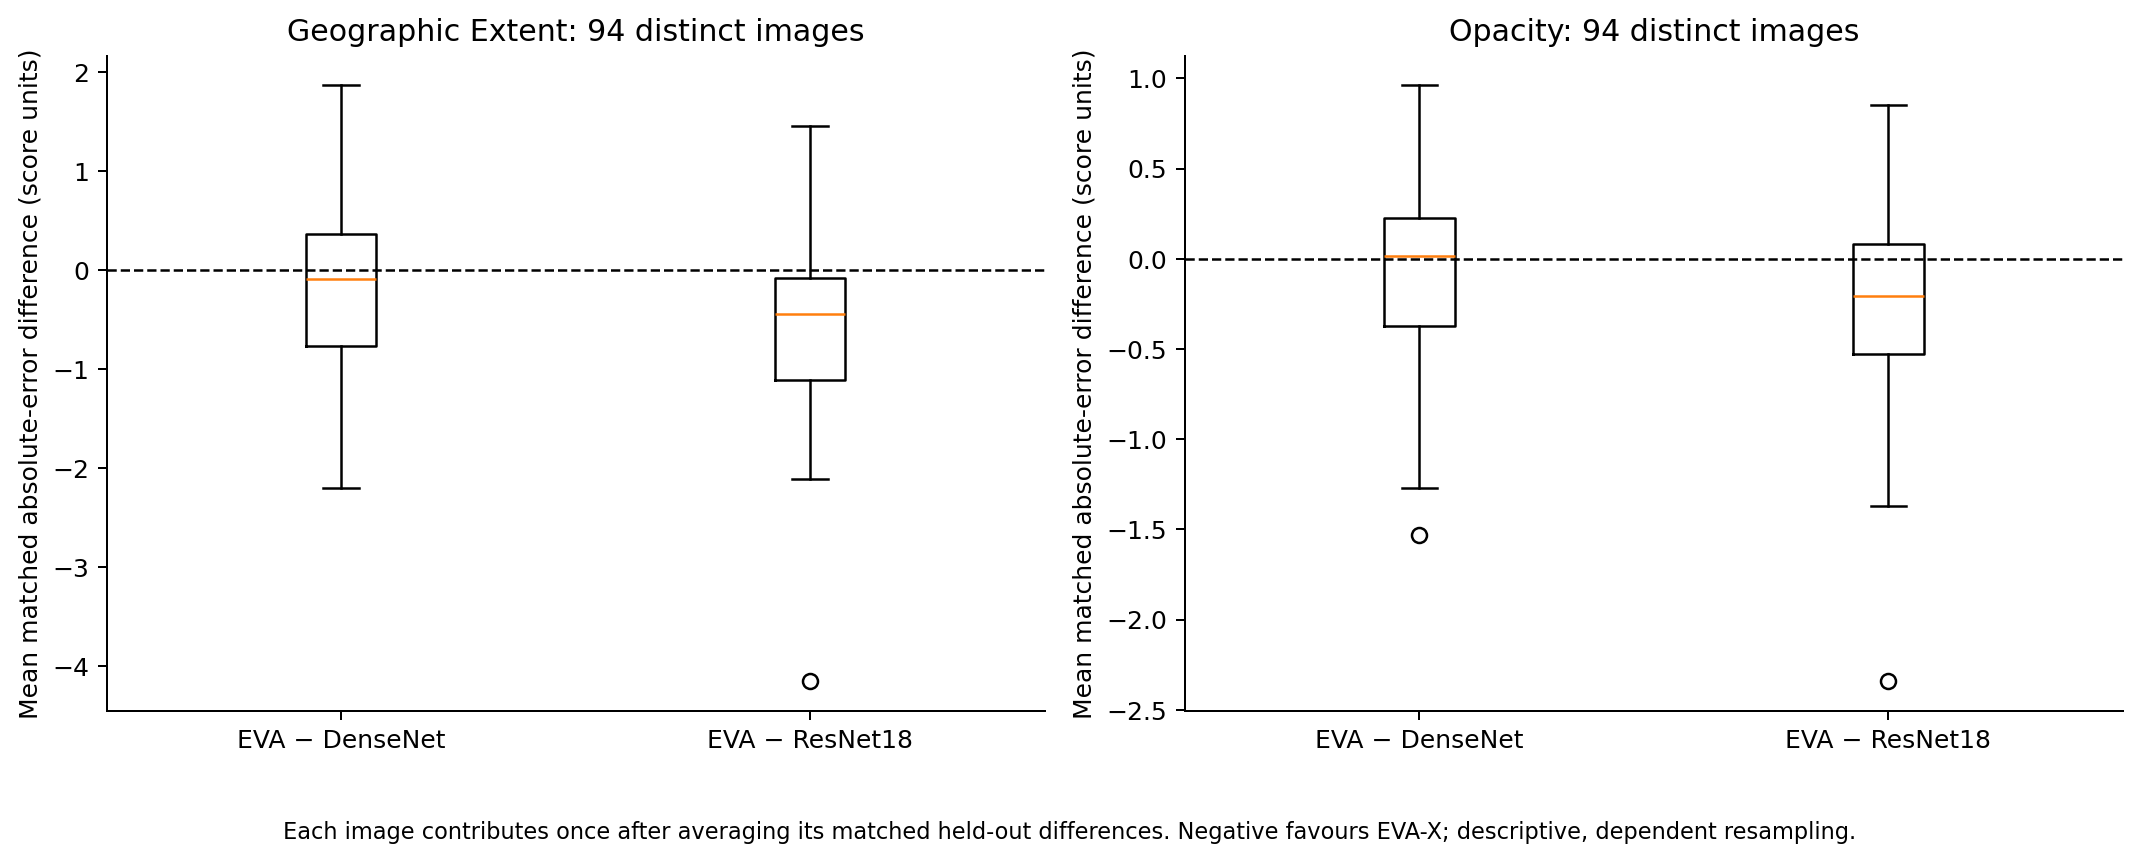

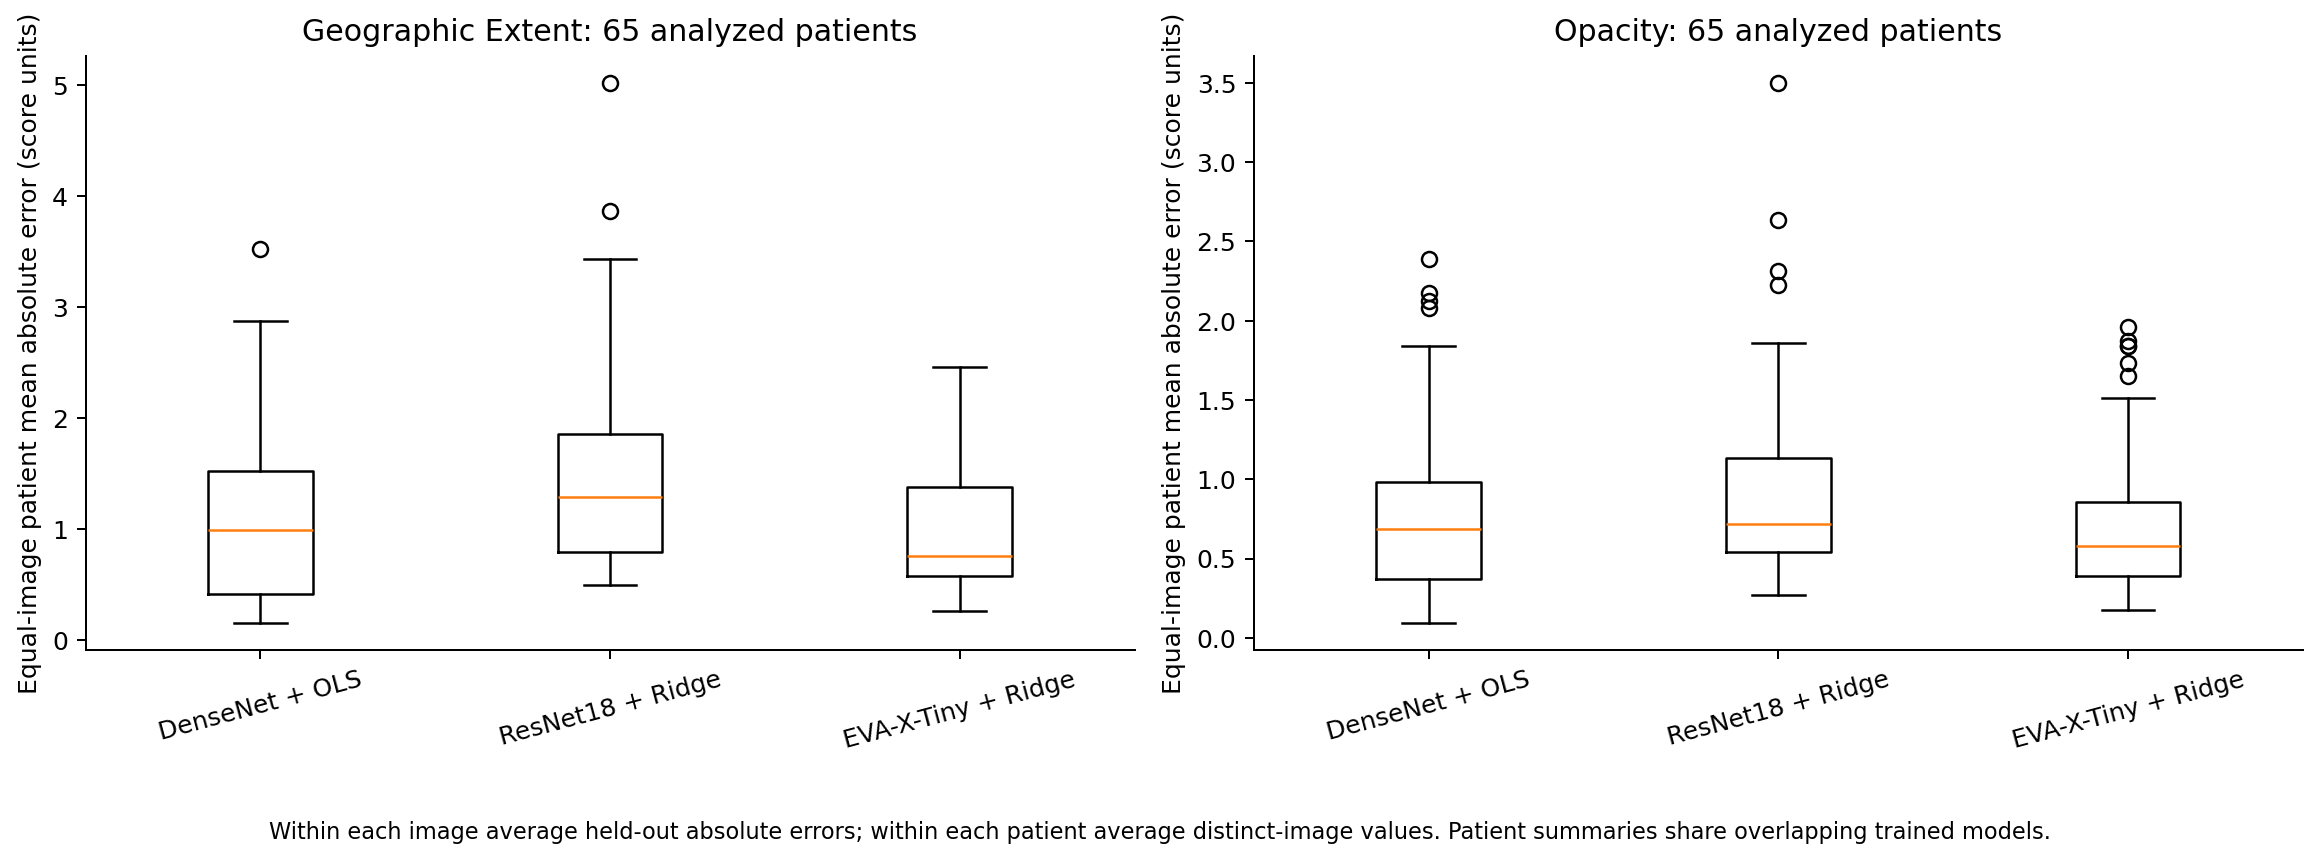

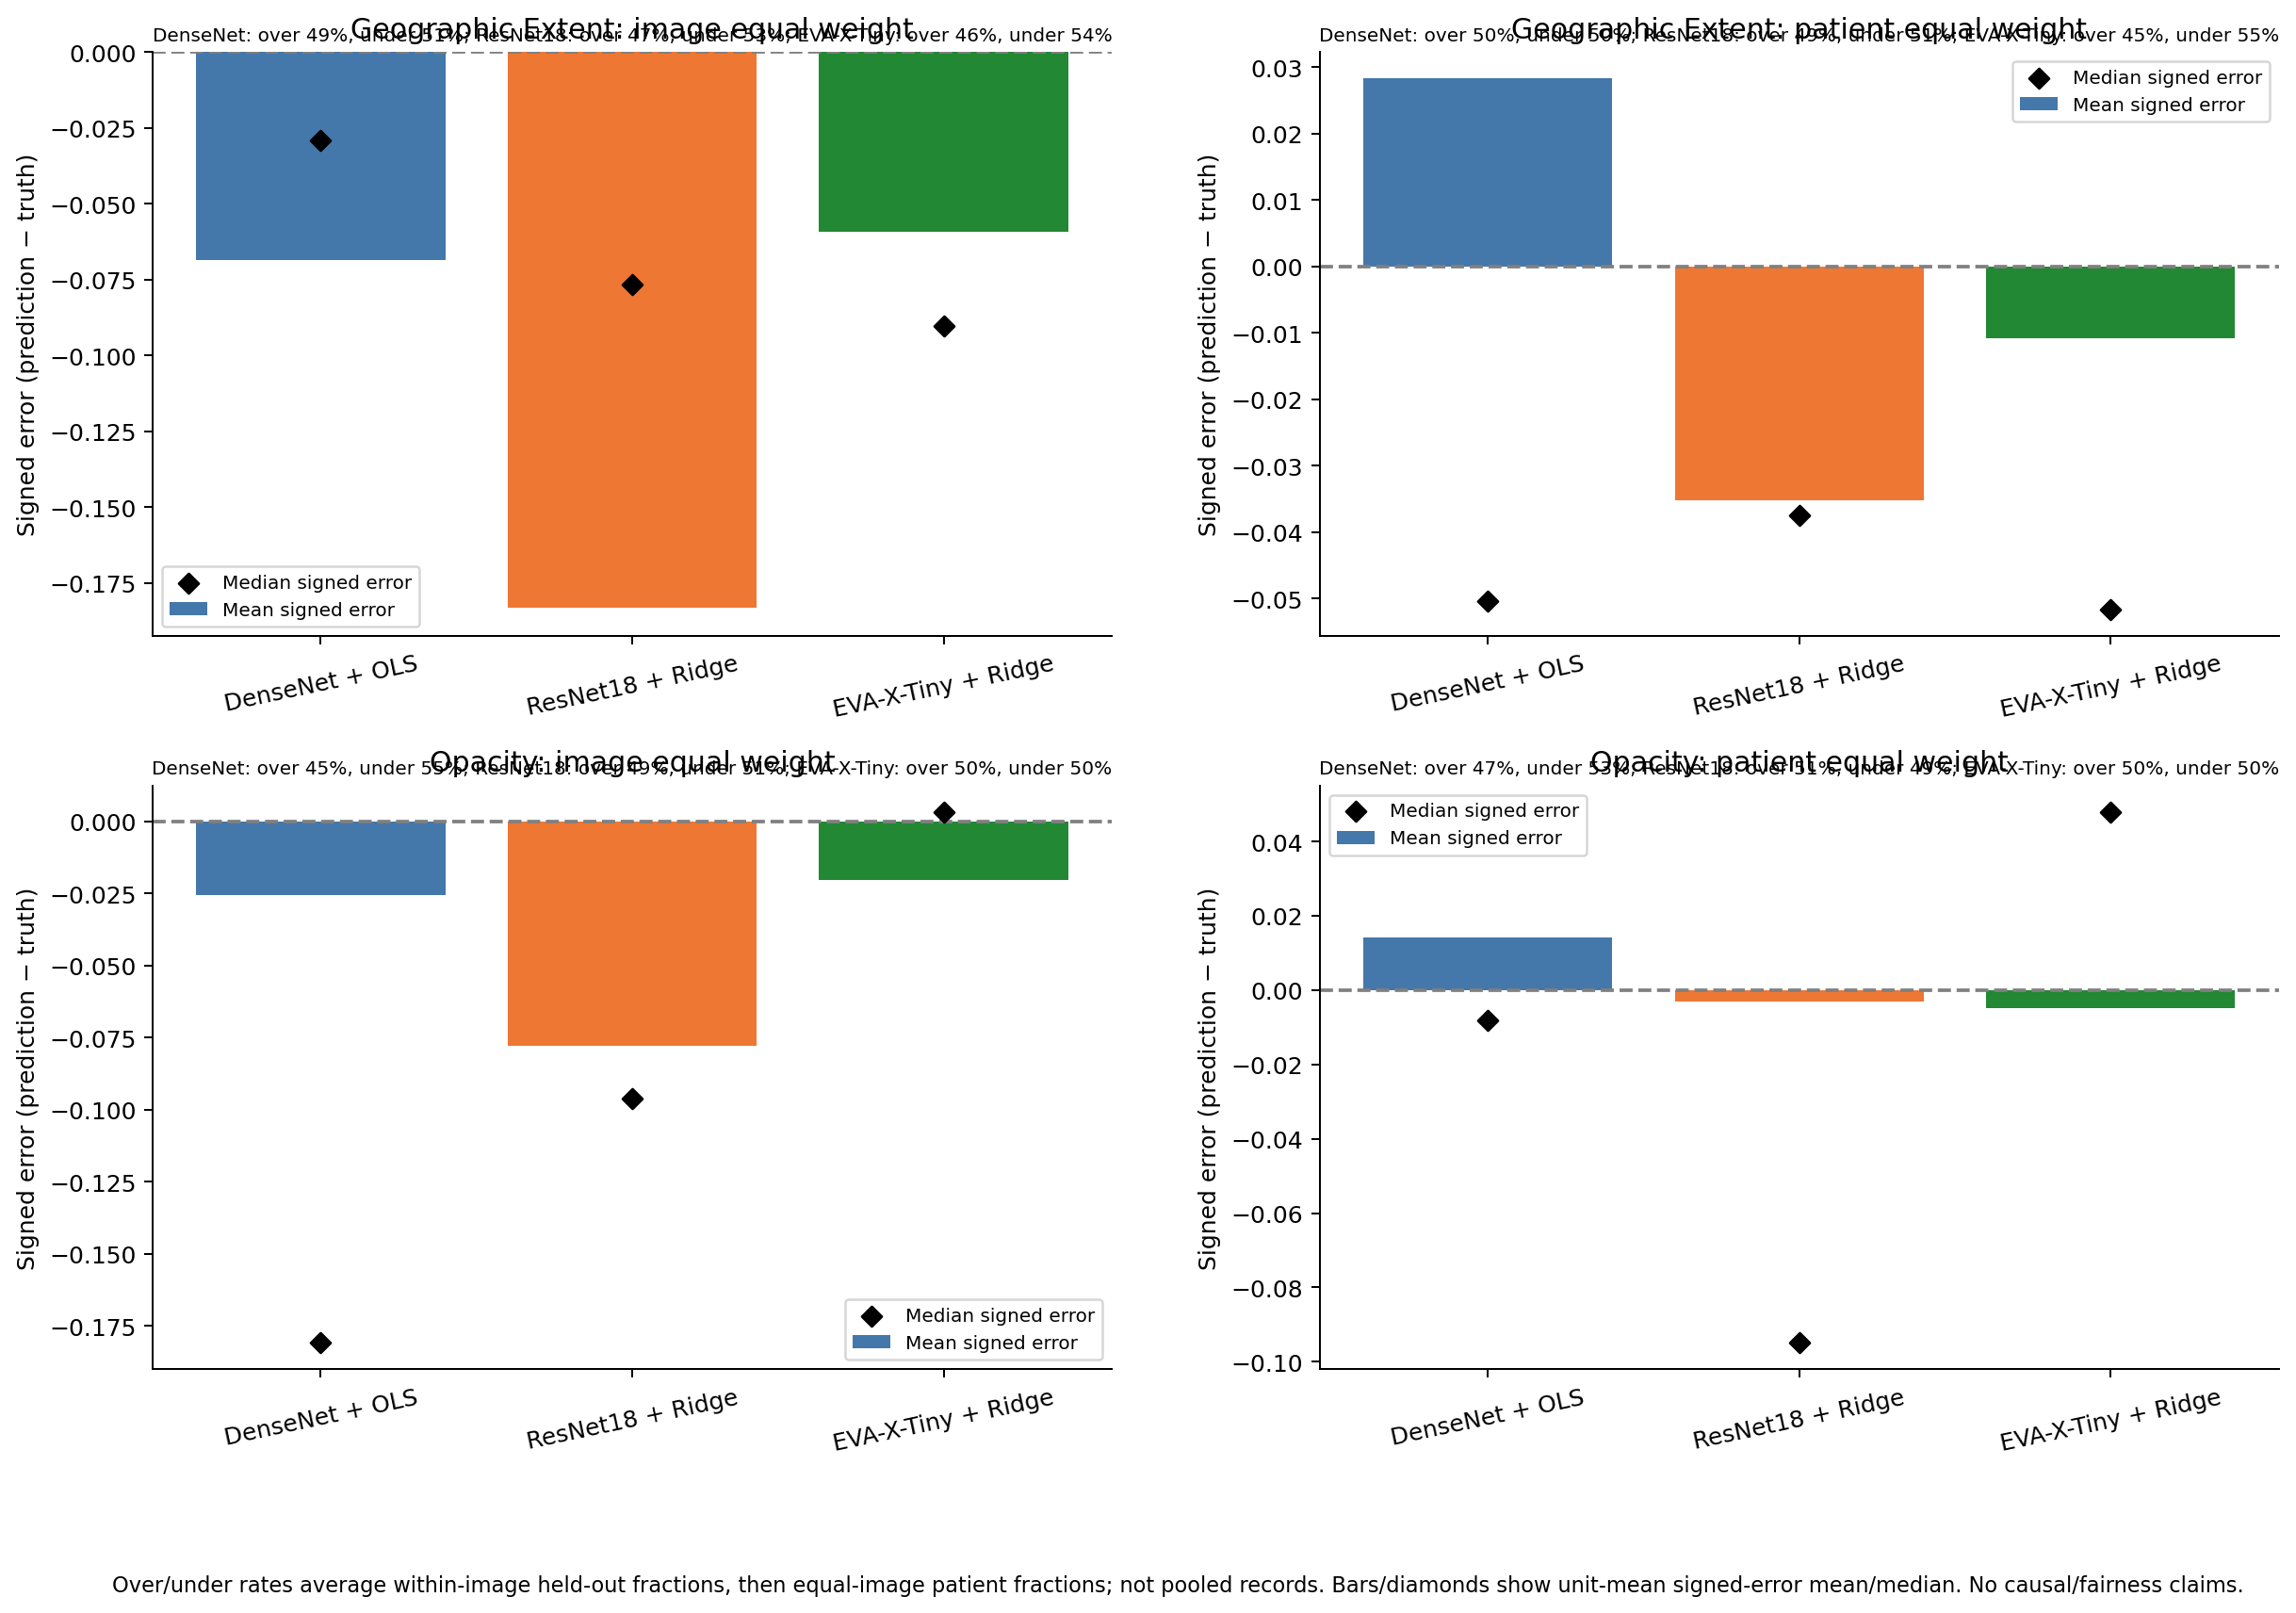

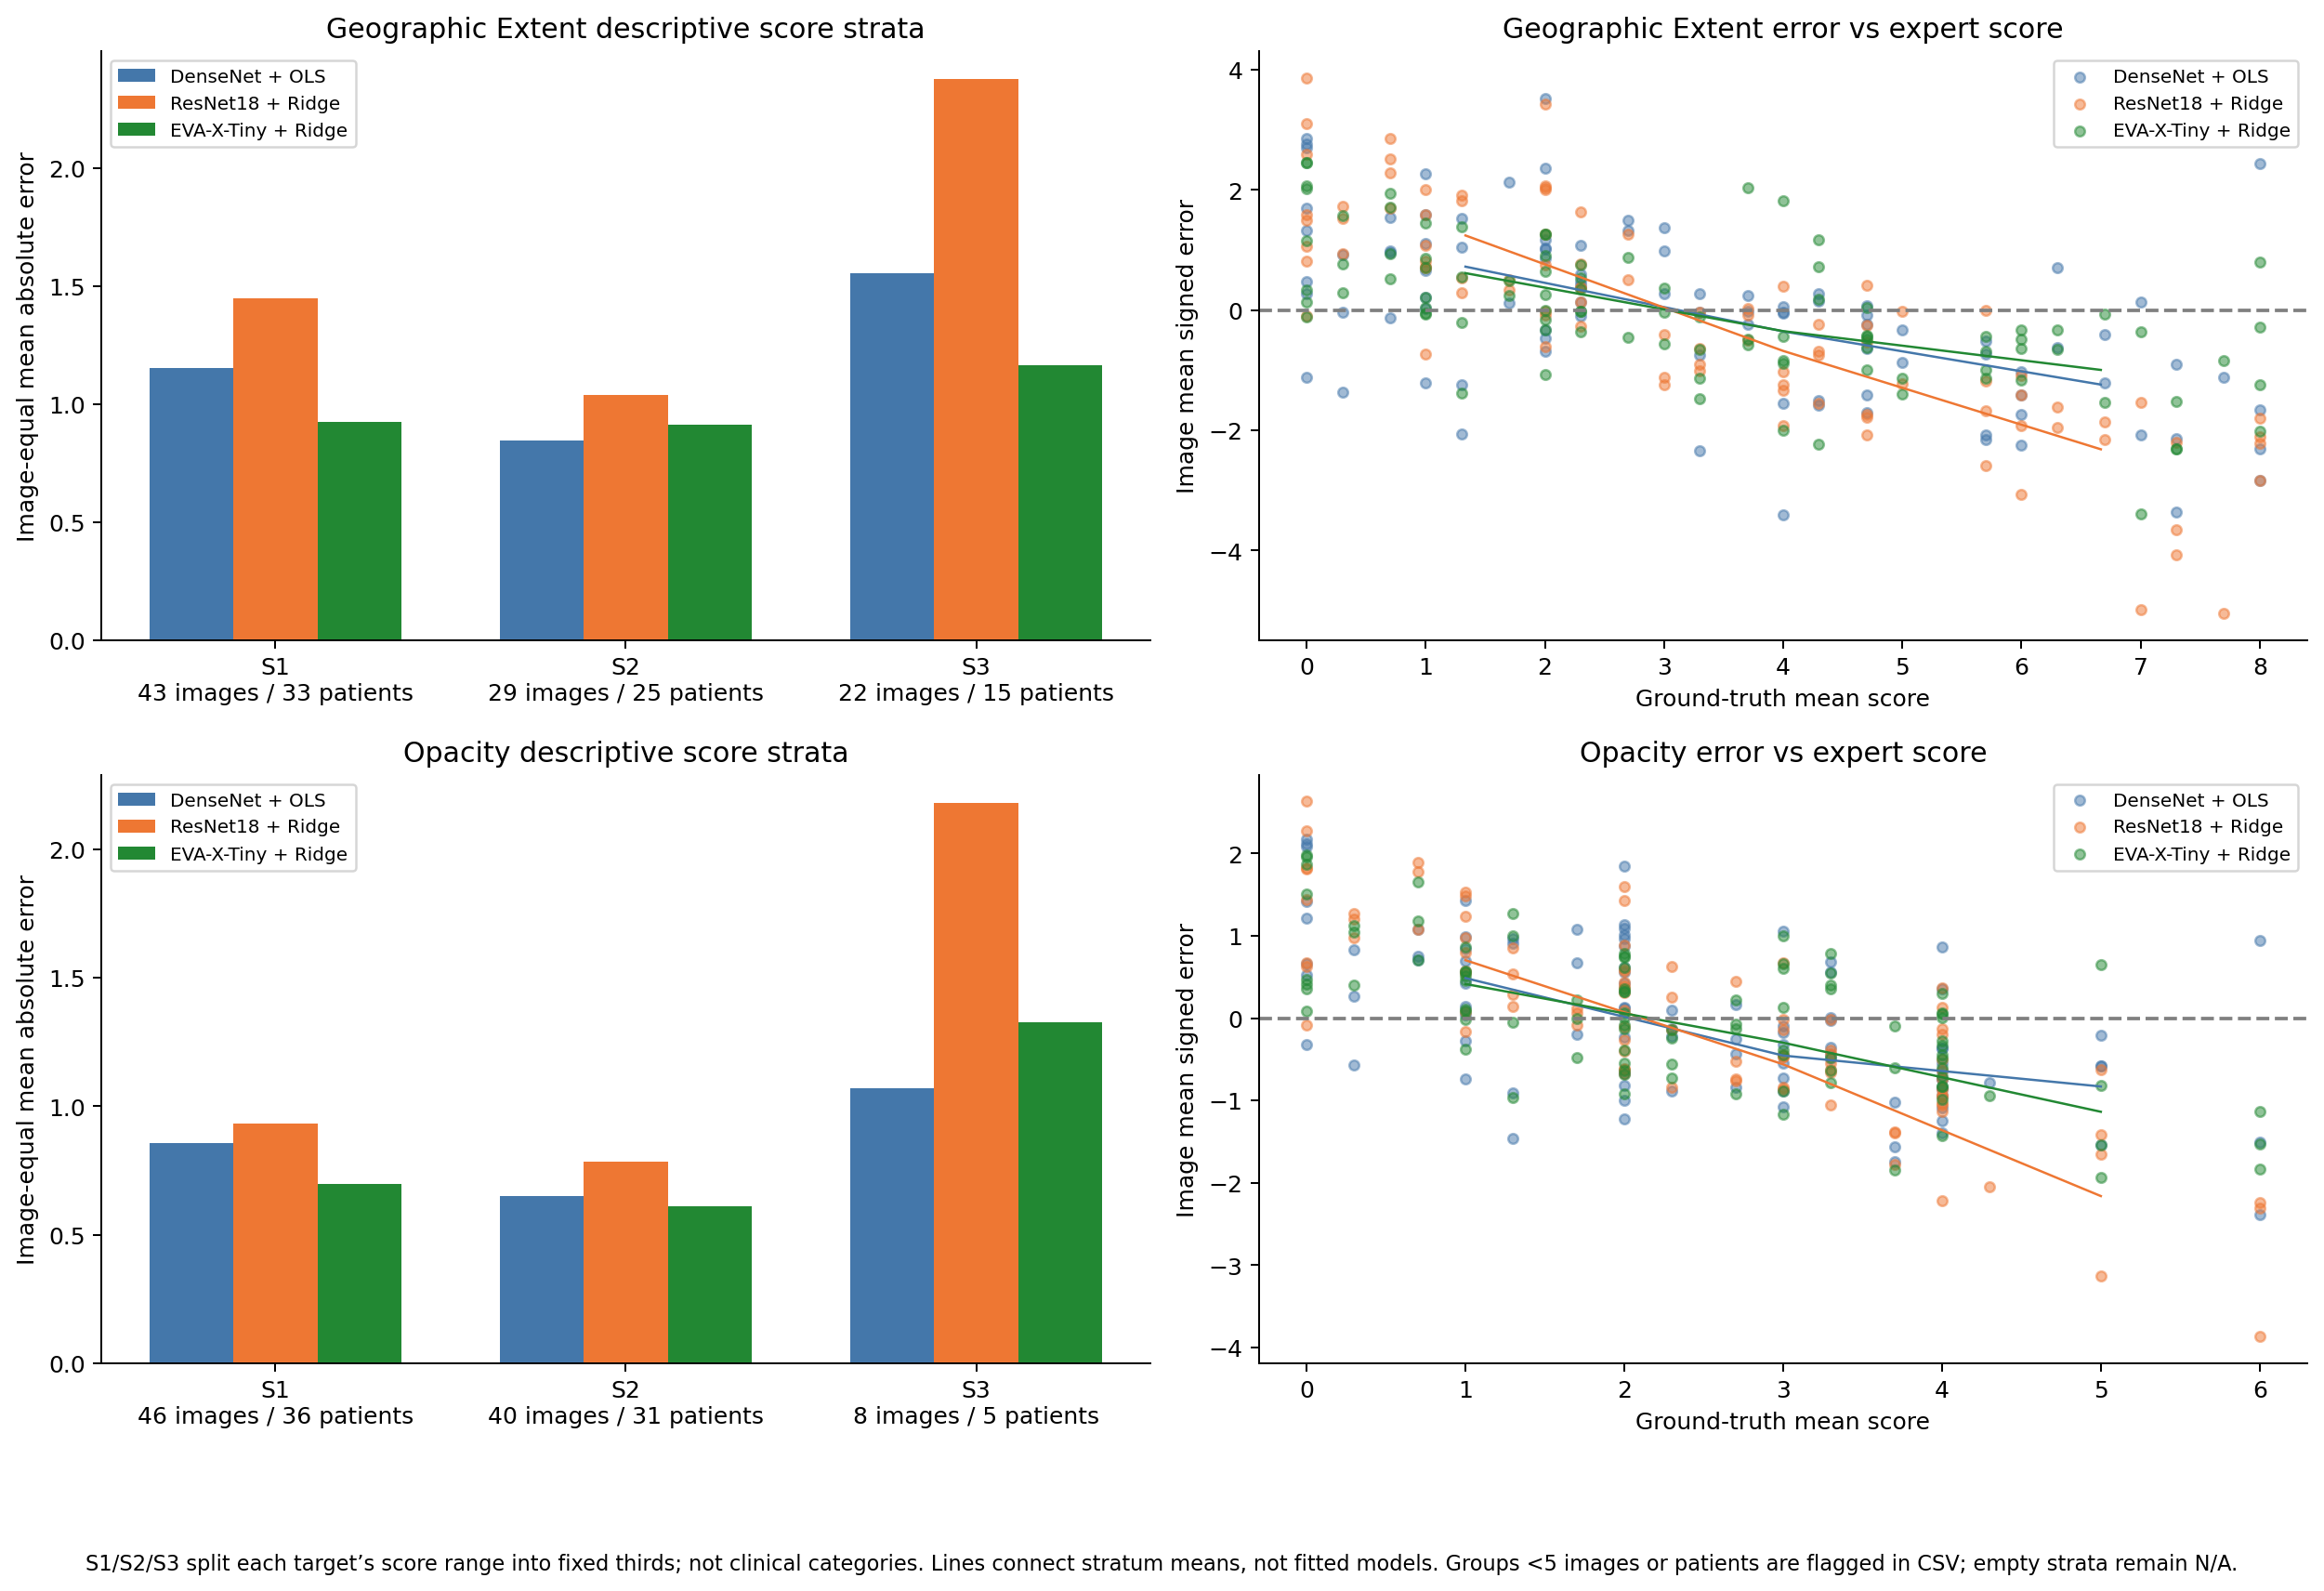

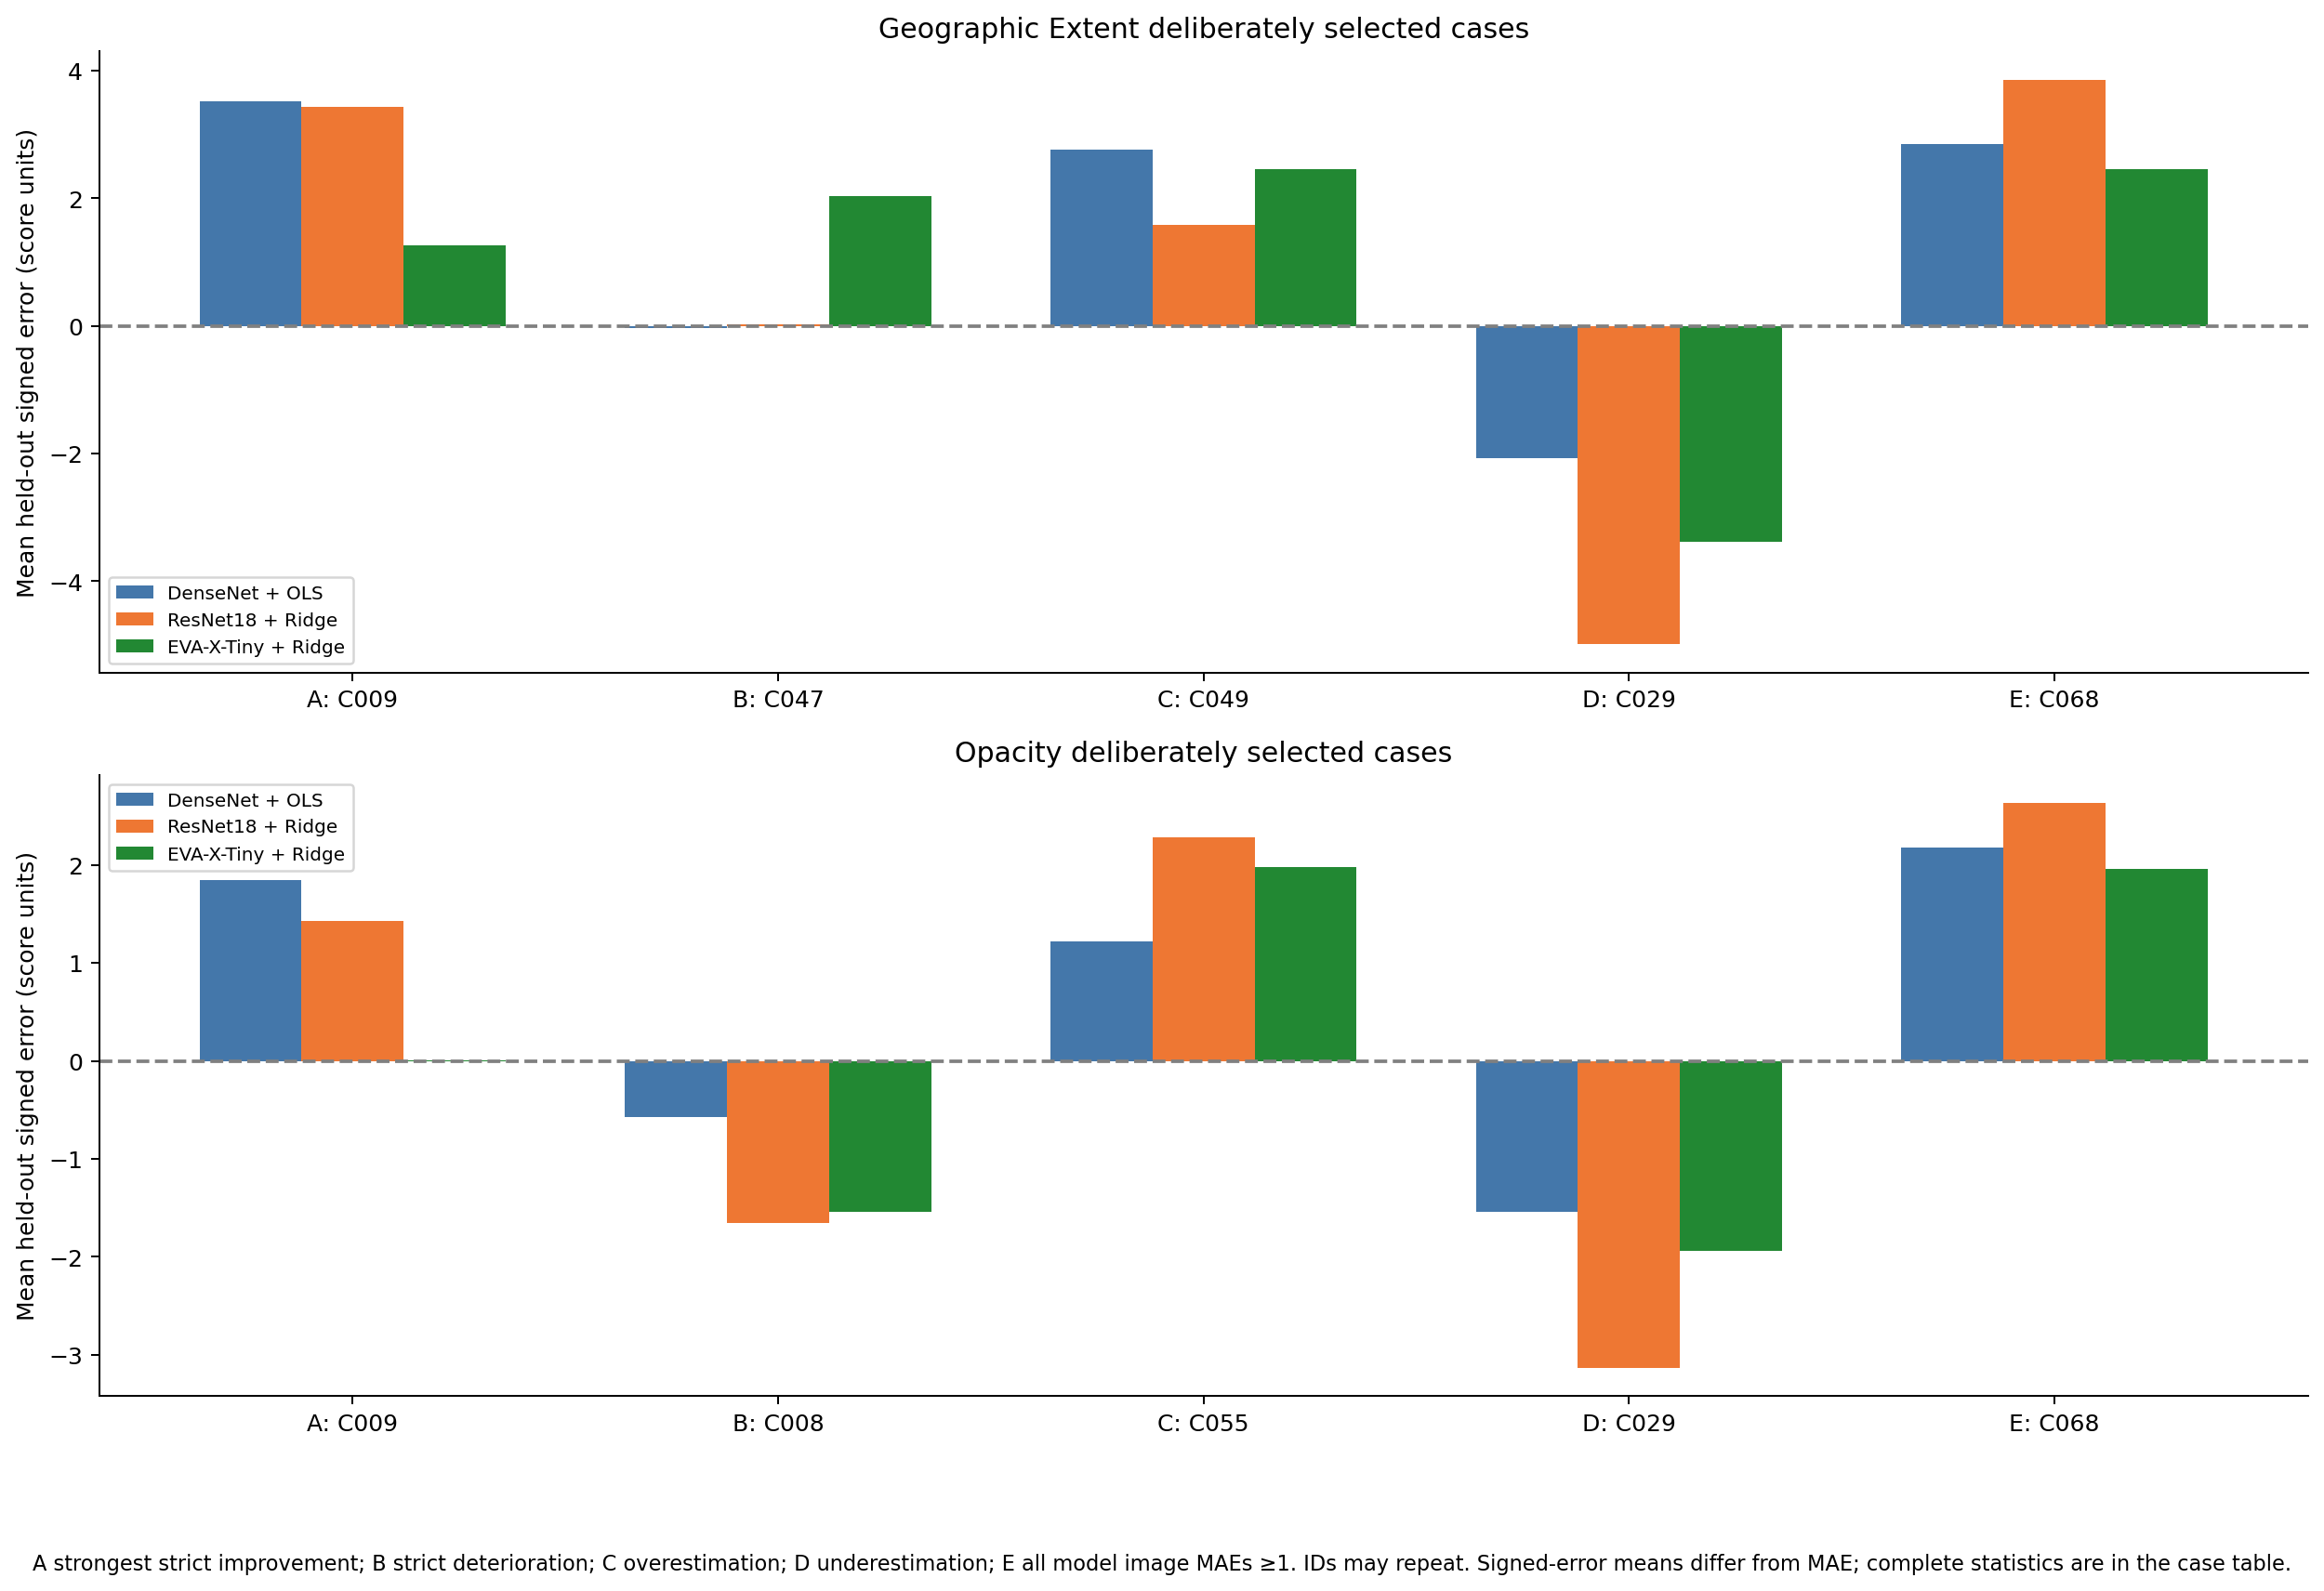

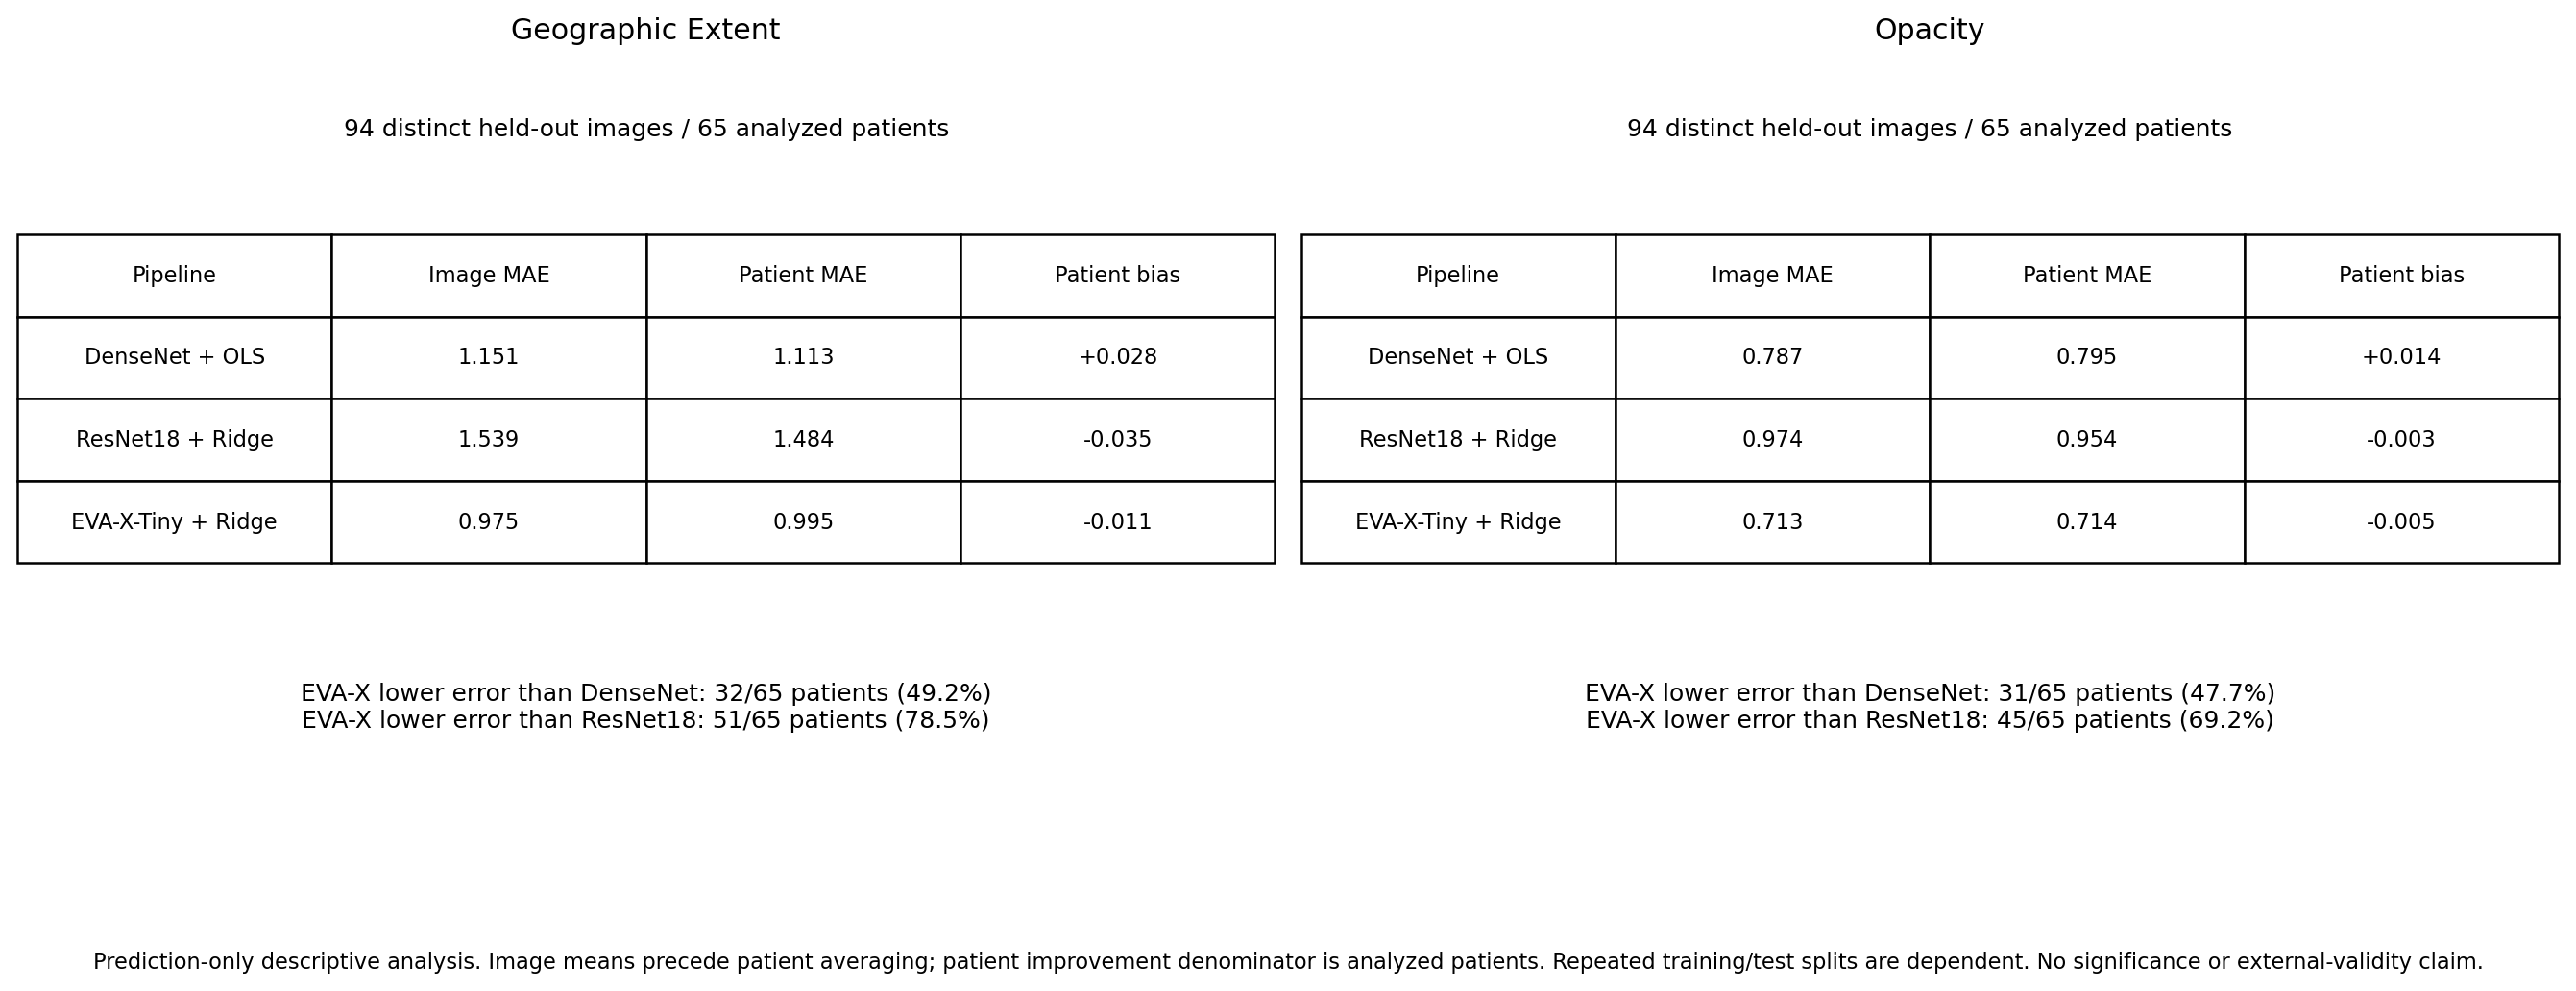

In [17]:
for key,path in input_paths.items():
    if file_sha256(path)!=input_hashes[key]:raise RuntimeError('Input changed during analysis; stop and reload consistent artifacts')
analysis_manifest=export_analysis(tables,cohort,validation,OUTPUT_DIR,input_paths,source_manifest,synthetic_fixture=False)
print('New results saved to:',OUTPUT_DIR)
for name in FIGURE_NAMES:display(Image(filename=str(OUTPUT_DIR/name)))


## Lecture 9: critical assessment and limits
**Appropriate metrics:** signed error identifies direction, MAE captures magnitude without cancellation, squared error exposes large residuals, paired differences compare identical held-out observations, and hierarchical averaging makes the unit and weighting explicit. No percentage metric with a zero-denominator problem is introduced for zero scores.

**Interpretability:** error-vs-score plots and deliberately selected numerical cases explain observable failure patterns, not model attention, lesion localization or causation. Selection extremes and small strata are labelled. No fourth model, feature extraction, parameter refit or hyperparameter tuning occurs.

**Reproducibility:** source-export inspection, strict paired identity/membership checks, input hashes, original provenance, declared thresholds/tie-breaking, package versions and private mappings support auditability. All notebook outputs are empty until actual files pass validation. No clinical findings are inferred from synthetic fixtures or supplied summary means.

**Generalizability:** 94 images from 65 patients, annotation uncertainty, convenience sampling, possible upstream pretraining overlap and shared training sets constrain interpretation. Results are descriptive for these repeated internal splits; even broad patient-level improvement would not establish external validity, independent-patient inference, clinical benefit or statistical significance. Differences may reflect complete pretrained pipelines and data composition. Causal, fairness, localization and deployment claims require additional evidence.

**Execution status:** real prediction artifacts are absent in the development workspace. Only unit/synthetic integration tests can be executed there. No real patient rankings, improvement proportions, bias conclusions or study figures are supplied until this notebook runs on the real CSV and audit.
